In [ ]:
# Paths (relative to the repository root, so the notebooks run on any machine)
# Expected layout:  <repo>/notebooks/ (this file), <repo>/data/, <repo>/models/,
#                   <repo>/figures/, <repo>/results/, <repo>/feature_importance/
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = ROOT / "data"
MODELS_DIR = ROOT / "models"
FIG_DIR = ROOT / "figures"
RESULTS_DIR = ROOT / "results"
FI_DIR = ROOT / "feature_importance"
for _d in (DATA_DIR, MODELS_DIR, FIG_DIR, RESULTS_DIR, FI_DIR):
    _d.mkdir(parents=True, exist_ok=True)


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
# Ignore warnings
import warnings
warnings.filterwarnings("ignore")

# Display all columns
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Libraries Imported Successfully")

Libraries Imported Successfully


In [2]:
df = pd.read_csv(str(DATA_DIR / "MetalCytoToxDB.csv"))

In [3]:
df

,SMILES_Ligands,Counterion,Abbreviation_in_the_article,IC50_Dark(M*10^-6),IC50_Dark_standard_error(M*10^-6),IC50_Dark_value,IC50_Light(M*10^-6),IC50_Light_standard_error(M*10^-6),IC50_Light_value,Excitation_Wavelength(nm),Irradiation_Time(minutes),Irradiation_Power(W*m^-2),Cell_line,Time(h),DOI,Year,IC50_Cisplatin(M*10^-6),IC50_Cisplatin_standard_error(M*10^-6),IC50_Cisplatin_value,Charge_complex,Metal,Oxidation_state,Atomic_number,Valence_e
0,N#Cc1ccc(C(c2ccc(C#N)cc2)n2cncn2)cc1.N#Cc1ccc(...,F[B-](F)(F)F,5,36,6.000,36.00,NaN,NaN,NaN,NaN,NaN,NaN,MCF-7,24.0,10.1021/jm301103y,2012,NaN,NaN,NaN,1,Ru,2,44,8
1,COc1cc(/C=C/C(=O)/C=C([O-])/C=C/c2ccc(O)c(OC)c...,NaN,Ru-Cur,19.58,2.367,19.58,NaN,NaN,NaN,NaN,NaN,NaN,MCF-7,72.0,10.1021/jm200912j,2012,1.835,0.237,1.835,0,Ru,2,44,8
2,COc1cc(/C=C/C(=O)/C=C([O-])/C=C/c2ccc(O)c(OC)c...,NaN,Ru-Cur,13.98,1.503,13.98,NaN,NaN,NaN,NaN,NaN,NaN,HCT-116,72.0,10.1021/jm200912j,2012,5.217,0.348,5.217,0,Ru,2,44,8
3,COc1cc(/C=C/C(=O)/C=C([O-])/C=C/c2ccc(O)c(OC)c...,NaN,Ru-Cur,23.38,3.334,23.38,NaN,NaN,NaN,NaN,NaN,NaN,A2780,72.0,10.1021/jm200912j,2012,1.325,0.196,1.325,0,Ru,2,44,8
4,COc1cc(/C=C/C(=O)/C=C([O-])/C=C/c2ccc(O)c(OC)c...,NaN,Ru-Cur,27,2.332,27.00,NaN,NaN,NaN,NaN,NaN,NaN,CP8,72.0,10.1021/jm200912j,2012,9.918,1.155,9.918,0,Ru,2,44,8
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
26796,C1=CCCC=CCC1.Ic1ccc(Cn2[c-][n+](CCC[P+](c3cccc...,NaN,5a,9,2.200,9.00,NaN,NaN,NaN,NaN,NaN,NaN,HT-29,72.0,10.1002/ejic.201300820,2013,NaN,NaN,NaN,0,Rh,1,45,9
26797,C1=CCCC=CCC1.O=S(=O)(O)CCC[n+]1[c-]n(Cc2ccc(I)...,NaN,4a,>100,NaN,100.00,NaN,NaN,NaN,NaN,NaN,NaN,MDA-MB-231,72.0,10.1002/ejic.201300820,2013,NaN,NaN,NaN,0,Rh,1,45,9
26798,C1=CCCC=CCC1.Ic1ccc(Cn2[c-][n+](CCC[P+](c3cccc...,NaN,5a,14.7,5.600,14.70,NaN,NaN,NaN,NaN,NaN,NaN,MDA-MB-231,72.0,10.1002/ejic.201300820,2013,NaN,NaN,NaN,0,Rh,1,45,9
26799,C1=CCCC=CCC1.O=S(=O)(O)CCC[n+]1[c-]n(Cc2ccc(I)...,NaN,4a,67.3,9.100,67.30,NaN,NaN,NaN,NaN,NaN,NaN,L-929,72.0,10.1002/ejic.201300820,2013,NaN,NaN,NaN,0,Rh,1,45,9


In [4]:
print("Rows :", df.shape[0])
print("Columns :", df.shape[1])

Rows : 26801
Columns : 24


In [5]:
df.columns

Index(['SMILES_Ligands', 'Counterion', 'Abbreviation_in_the_article',
       'IC50_Dark(M*10^-6)', 'IC50_Dark_standard_error(M*10^-6)',
       'IC50_Dark_value', 'IC50_Light(M*10^-6)',
       'IC50_Light_standard_error(M*10^-6)', 'IC50_Light_value',
       'Excitation_Wavelength(nm)', 'Irradiation_Time(minutes)',
       'Irradiation_Power(W*m^-2)', 'Cell_line', 'Time(h)', 'DOI', 'Year',
       'IC50_Cisplatin(M*10^-6)', 'IC50_Cisplatin_standard_error(M*10^-6)',
       'IC50_Cisplatin_value', 'Charge_complex', 'Metal', 'Oxidation_state',
       'Atomic_number', 'Valence_e'],
      dtype='str')

In [6]:
for col in df.columns:
    print(col)

SMILES_Ligands
Counterion
Abbreviation_in_the_article
IC50_Dark(M*10^-6)
IC50_Dark_standard_error(M*10^-6)
IC50_Dark_value
IC50_Light(M*10^-6)
IC50_Light_standard_error(M*10^-6)
IC50_Light_value
Excitation_Wavelength(nm)
Irradiation_Time(minutes)
Irradiation_Power(W*m^-2)
Cell_line
Time(h)
DOI
Year
IC50_Cisplatin(M*10^-6)
IC50_Cisplatin_standard_error(M*10^-6)
IC50_Cisplatin_value
Charge_complex
Metal
Oxidation_state
Atomic_number
Valence_e


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 26801 entries, 0 to 26800
Data columns (total 24 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   SMILES_Ligands                          26801 non-null  str    
 1   Counterion                              18044 non-null  str    
 2   Abbreviation_in_the_article             26801 non-null  str    
 3   IC50_Dark(M*10^-6)                      26801 non-null  str    
 4   IC50_Dark_standard_error(M*10^-6)       18503 non-null  float64
 5   IC50_Dark_value                         26801 non-null  float64
 6   IC50_Light(M*10^-6)                     2158 non-null   str    
 7   IC50_Light_standard_error(M*10^-6)      1737 non-null   float64
 8   IC50_Light_value                        2158 non-null   float64
 9   Excitation_Wavelength(nm)               2113 non-null   str    
 10  Irradiation_Time(minutes)               2079 non-null   float64
 11  

In [8]:
df.describe()

,IC50_Dark_standard_error(M*10^-6),IC50_Dark_value,IC50_Light_standard_error(M*10^-6),IC50_Light_value,Irradiation_Time(minutes),Irradiation_Power(W*m^-2),Time(h),Year,IC50_Cisplatin_standard_error(M*10^-6),IC50_Cisplatin_value,Charge_complex,Oxidation_state,Atomic_number,Valence_e
count,18503.000000,26801.000000,1737.000000,2158.000000,2079.000000,1870.000000,26612.000000,26801.000000,11962.000000,14309.000000,26801.000000,26801.000000,26801.000000,26801.000000
mean,3.095699,66.069065,1.100747,26.235910,34.613970,331.058529,55.350162,2018.232864,1.590506,19.839150,0.823066,2.223126,51.978658,8.179546
std,10.433191,131.509254,2.419563,55.922784,39.013742,768.685824,24.693007,4.625512,4.325411,41.419212,0.836771,0.498270,13.962348,0.460533
min,0.000000,0.002000,0.000000,0.000200,0.167000,2.700000,1.000000,2001.000000,0.000000,0.039000,-4.000000,1.000000,44.000000,7.000000
25%,0.260000,5.700000,0.050000,0.570000,10.000000,40.000000,48.000000,2015.000000,0.300000,5.580000,0.000000,2.000000,44.000000,8.000000
50%,0.980000,23.000000,0.300000,3.900000,25.000000,80.830000,48.000000,2019.000000,0.890000,12.000000,1.000000,2.000000,44.000000,8.000000
75%,2.600000,92.560000,1.200000,21.675000,60.000000,239.000000,72.000000,2022.000000,1.800000,21.800000,1.000000,3.000000,45.000000,8.000000
max,738.000000,8157.000000,51.900000,1140.000000,240.000000,6000.000000,168.000000,2025.000000,126.000000,2200.000000,8.000000,5.000000,77.000000,9.000000


In [9]:
df.describe(include="object")

,SMILES_Ligands,Counterion,Abbreviation_in_the_article,IC50_Dark(M*10^-6),IC50_Light(M*10^-6),Excitation_Wavelength(nm),Cell_line,DOI,IC50_Cisplatin(M*10^-6),Metal
count,26801,18044,26801,26801,2158,2113,26801,26801,14309,26801
unique,6782,68,1999,5503,920,68,754,1921,1512,5
top,[Cl-].[Cl-].[Cl-].[Cl-].c1ccc2[nH]ncc2c1.c1ccc...,F[P-](F)(F)(F)(F)F,1,>100,>100,450,A549,10.3390/cancers15010028,7.5,Ru
freq,403,7529,2355,2230,138,306,2994,311,170,19135


In [10]:
missing = df.isnull().sum()
missing = missing[missing > 0]

missing.sort_values(ascending=False)

IC50_Light_standard_error(M*10^-6)        25064
Irradiation_Power(W*m^-2)                 24931
Irradiation_Time(minutes)                 24722
Excitation_Wavelength(nm)                 24688
IC50_Light(M*10^-6)                       24643
IC50_Light_value                          24643
IC50_Cisplatin_standard_error(M*10^-6)    14839
IC50_Cisplatin(M*10^-6)                   12492
IC50_Cisplatin_value                      12492
Counterion                                 8757
IC50_Dark_standard_error(M*10^-6)          8298
Time(h)                                     189
dtype: int64

In [11]:
missing_percent = (df.isnull().sum() / len(df)) * 100

missing_percent = missing_percent[missing_percent > 0]

missing_percent.sort_values(ascending=False)

IC50_Light_standard_error(M*10^-6)        93.518899
Irradiation_Power(W*m^-2)                 93.022648
Irradiation_Time(minutes)                 92.242827
Excitation_Wavelength(nm)                 92.115966
IC50_Light(M*10^-6)                       91.948062
IC50_Light_value                          91.948062
IC50_Cisplatin_standard_error(M*10^-6)    55.367337
IC50_Cisplatin(M*10^-6)                   46.610201
IC50_Cisplatin_value                      46.610201
Counterion                                32.674154
IC50_Dark_standard_error(M*10^-6)         30.961531
Time(h)                                    0.705198
dtype: float64

In [12]:
print(df.duplicated().sum())

0


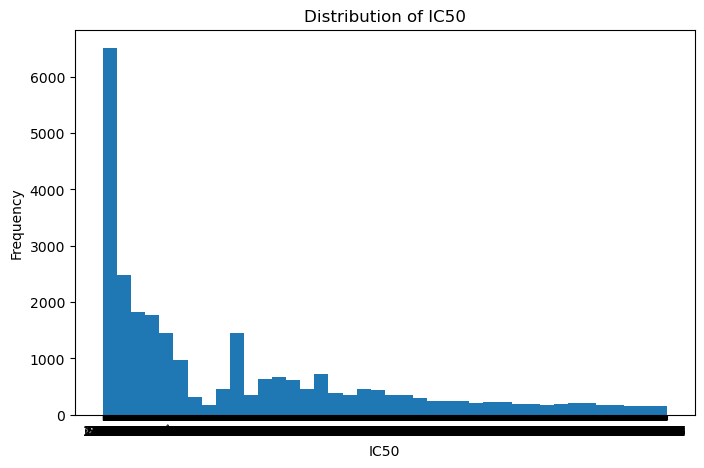

In [13]:
plt.figure(figsize=(8,5))
plt.hist(df["IC50_Dark(M*10^-6)"], bins=40)
plt.title("Distribution of IC50")
plt.xlabel("IC50")
plt.ylabel("Frequency")
plt.show()

In [14]:
df.head()

,SMILES_Ligands,Counterion,Abbreviation_in_the_article,IC50_Dark(M*10^-6),IC50_Dark_standard_error(M*10^-6),IC50_Dark_value,IC50_Light(M*10^-6),IC50_Light_standard_error(M*10^-6),IC50_Light_value,Excitation_Wavelength(nm),Irradiation_Time(minutes),Irradiation_Power(W*m^-2),Cell_line,Time(h),DOI,Year,IC50_Cisplatin(M*10^-6),IC50_Cisplatin_standard_error(M*10^-6),IC50_Cisplatin_value,Charge_complex,Metal,Oxidation_state,Atomic_number,Valence_e
0,N#Cc1ccc(C(c2ccc(C#N)cc2)n2cncn2)cc1.N#Cc1ccc(...,F[B-](F)(F)F,5,36,6.000,36.00,NaN,NaN,NaN,NaN,NaN,NaN,MCF-7,24.0,10.1021/jm301103y,2012,NaN,NaN,NaN,1,Ru,2,44,8
1,COc1cc(/C=C/C(=O)/C=C([O-])/C=C/c2ccc(O)c(OC)c...,NaN,Ru-Cur,19.58,2.367,19.58,NaN,NaN,NaN,NaN,NaN,NaN,MCF-7,72.0,10.1021/jm200912j,2012,1.835,0.237,1.835,0,Ru,2,44,8
2,COc1cc(/C=C/C(=O)/C=C([O-])/C=C/c2ccc(O)c(OC)c...,NaN,Ru-Cur,13.98,1.503,13.98,NaN,NaN,NaN,NaN,NaN,NaN,HCT-116,72.0,10.1021/jm200912j,2012,5.217,0.348,5.217,0,Ru,2,44,8
3,COc1cc(/C=C/C(=O)/C=C([O-])/C=C/c2ccc(O)c(OC)c...,NaN,Ru-Cur,23.38,3.334,23.38,NaN,NaN,NaN,NaN,NaN,NaN,A2780,72.0,10.1021/jm200912j,2012,1.325,0.196,1.325,0,Ru,2,44,8
4,COc1cc(/C=C/C(=O)/C=C([O-])/C=C/c2ccc(O)c(OC)c...,NaN,Ru-Cur,27,2.332,27.00,NaN,NaN,NaN,NaN,NaN,NaN,CP8,72.0,10.1021/jm200912j,2012,9.918,1.155,9.918,0,Ru,2,44,8
